In [1]:
import pandas as pd
df=pd.read_csv("penguins.csv")

print(df.shape)

(344, 8)


In [2]:
print(df.isna().sum())

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64


In [3]:
print(df["species"].value_counts())

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


AI Tool: Gemini
Prompt Log: You are helping with exploratory data analysis.
My CSV has columns:  ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'year'].
Write Python using pandas and seaborn to:
(1) summarize missing data,
(2) compare mean flipper length across species,
(3) produce one labeled chart.
Explain each step in comments. 

--- Missing Data Summary ---
                   Missing Count  Missing Percentage (%)
bill_length_mm                 2                    0.58
bill_depth_mm                  2                    0.58
flipper_length_mm              2                    0.58
body_mass_g                    2                    0.58
sex                           11                    3.20


--- Mean Flipper Length by Species ---
  species  mean_flipper_length_mm
   Adelie              189.953642
Chinstrap              195.823529
   Gentoo              217.186992




C:\Users\kyepu\AppData\Local\Temp\ipykernel_17716\1717143709.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


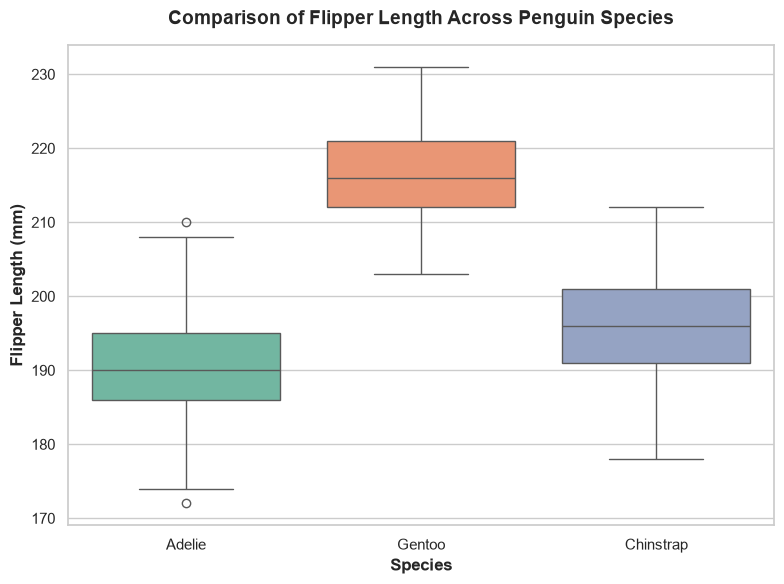

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load your dataset
df = pd.read_csv('penguins.csv')

# ==========================================
# (1) Summarize missing data
# ==========================================
# Calculate total missing values and their percentage per column
missing_count = df.isnull().sum()
missing_percentage = (df.isnull().mean() * 100).round(2)

# Combine into a clean summary DataFrame
missing_summary = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Percentage (%)': missing_percentage
})

print("--- Missing Data Summary ---")
print(missing_summary[missing_summary['Missing Count'] > 0])
print("\n" + "="*40 + "\n")

# ==========================================
# (2) Compare mean flipper length across species
# ==========================================
# Group by species and compute the average flipper length
mean_flipper = df.groupby('species')['flipper_length_mm'].mean().reset_index()
mean_flipper.rename(columns={'flipper_length_mm': 'mean_flipper_length_mm'}, inplace=True)

print("--- Mean Flipper Length by Species ---")
print(mean_flipper.to_string(index=False))
print("\n" + "="*40 + "\n")

# ==========================================
# (3) Produce one labeled chart
# ==========================================
# Set the visual style for seaborn
sns.set_theme(style="whitegrid")

# Create a canvas for the plot
plt.figure(figsize=(8, 6))

# Generate a boxplot to visualize distribution and means across species
sns.boxplot(
    data=df, 
    x='species', 
    y='flipper_length_mm', 
    palette='Set2'
)

# Add clear labels and a title
plt.title('Comparison of Flipper Length Across Penguin Species', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Species', fontsize=12, fontweight='bold')
plt.ylabel('Flipper Length (mm)', fontsize=12, fontweight='bold')

# Adjust layout and display the chart
plt.tight_layout()
plt.show()

In [5]:
df.groupby("species")["flipper_length_mm"].mean()

species
Adelie       189.953642
Chinstrap    195.823529
Gentoo       217.186992
Name: flipper_length_mm, dtype: float64

The data from both the hand made and AI one match with each species having the same mean flipper length.

C:\Users\kyepu\AppData\Local\Temp\ipykernel_17716\2017310512.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


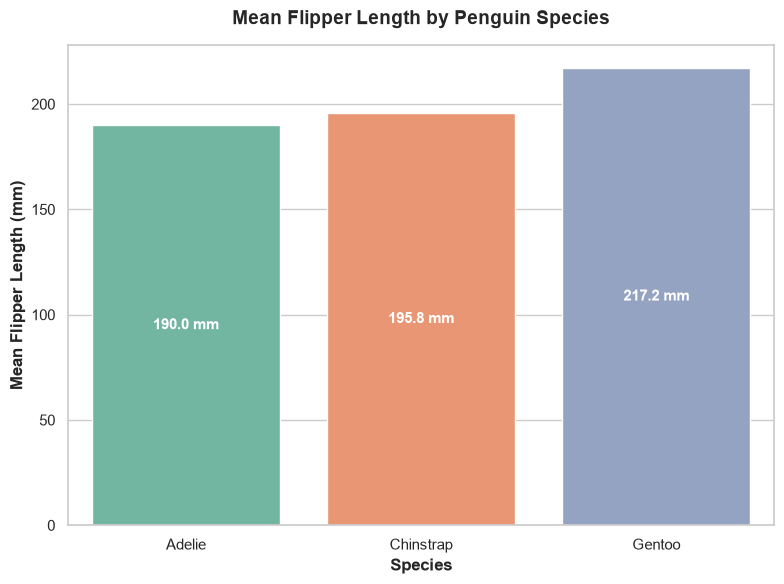

In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load your dataset (assuming it's named 'penguins.csv')
df = pd.read_csv('penguins.csv')

# Compute the mean flipper length grouped by species
mean_flipper = df.groupby('species')['flipper_length_mm'].mean().reset_index()
mean_flipper.rename(columns={'flipper_length_mm': 'mean_flipper_length_mm'}, inplace=True)

# Set the visual style for seaborn
sns.set_theme(style="whitegrid")

# Create a canvas for the plot
plt.figure(figsize=(8, 6))

# Generate a bar plot to visualize the mean flipper length across species
sns.barplot(
    data=mean_flipper, 
    x='species', 
    y='mean_flipper_length_mm', 
    palette='Set2'
)

# Add clear labels and a title
plt.title('Mean Flipper Length by Penguin Species', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Species', fontsize=12, fontweight='bold')
plt.ylabel('Mean Flipper Length (mm)', fontsize=12, fontweight='bold')

# Optional: Add data labels on top of the bars for quick reading
for index, row in mean_flipper.iterrows():
    plt.text(
        index, 
        row['mean_flipper_length_mm'] / 2, 
        f"{row['mean_flipper_length_mm']:.1f} mm", 
        color='white', 
        ha='center', 
        va='center', 
        fontweight='bold',
        fontsize=11
    )

# Adjust layout and display the chart
plt.tight_layout()
plt.show()

I asked for a bar chart to see how it would compare, and personally I would have the bar graph if I solely wanted to compare the means directly across species.

In [7]:
df.groupby("species")["sex"].value_counts()

species    sex   
Adelie     male      73
           female    73
Chinstrap  female    34
           male      34
Gentoo     male      61
           female    58
Name: count, dtype: int64

It is interesting to see how there are equal amounts both male and female for almost every species except for Gentoo where there is a difference of three female, it makes me wonder how different the data would be for mean weights of only male and female, if genders affect the mean flipper results and if gentoo could possibly have a lower mean.

In terms of data that should never be published in AI, Government Identification information such as social security numbers, Legal Name, and Addresses are personal information that should not be shared on the internet in general. The only real reason to enter the data would be on official government websites where you are required to give them such as the DMV. 

Repo Address- https://github.com/KyeSPu/cs82a-portfolio